In [1]:
print("ok")

ok


In [2]:
def hello_node(input:str):
    return {"message": f"Hello {input}!"}

In [3]:
hello_node("World")

{'message': 'Hello World!'}

In [4]:
hello_node("maha")

{'message': 'Hello maha!'}

In [5]:
hello_node("langgraph")

{'message': 'Hello langgraph!'}

In [6]:
from typing import TypedDict

In [7]:
class State(TypedDict):
    message: str

In [8]:
State(message="Hello World!")

{'message': 'Hello World!'}

In [9]:
def hello_node(state: State):
    return {"message": f"Hello {state['message']}!"}

In [10]:
from langgraph.graph import StateGraph, START, END 



In [11]:
builder= StateGraph(State)

In [12]:
builder.add_node("first_hello_node", hello_node)

In [13]:
builder.add_edge(START, "first_hello_node")

In [14]:
builder.add_edge("first_hello_node", END)

In [15]:
mygraph=builder.compile()

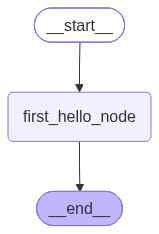

In [16]:
mygraph

In [17]:
mygraph.invoke({"message": "from india"})

{'message': 'Hello from india!'}

In [18]:
class Mahastate(TypedDict):
    text: str

In [19]:
state: Mahastate(text="Hello, World!")

In [20]:
def function01(state: Mahastate):
    print("function01 invoked")
    return {"text": f"Hello {state['text']}!"}

In [21]:
def function02(state: Mahastate):
    print("function02 invoked")
    return {"text": f"Hello {state['text']}!"}

In [22]:
workflow= StateGraph(Mahastate)

In [23]:
workflow.add_node("fun01", function01)
workflow.add_node("fun02", function02)

In [24]:
workflow.add_edge(START, "fun01")
workflow.add_edge("fun01", "fun02")
workflow.add_edge("fun02", END)

In [25]:
mygraph=workflow.compile()

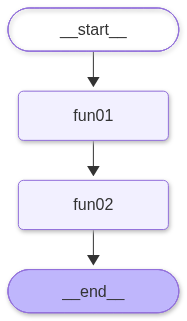

In [26]:
mygraph

In [27]:
myresult=mygraph.invoke({"text": "from india"})

function01 invoked
function02 invoked


In [28]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage

e:\MAHA\AIPRO\Agentic10PM\my10pmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [29]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [30]:
if not os.getenv("GROQ_API_KEY"):
    raise ValueError(
        "GROQ_API_KEY not found. Please add it to your .env file."
    )


In [31]:
MODEL_NAME = "openai/gpt-oss-20b"
llm = ChatGroq(
    model=MODEL_NAME,
    temperature=0.6,
    reasoning_format="hidden"
)

In [32]:
response = llm.invoke("Hi")

print(response.content)

Hello! 👋 How can I help you today?


In [33]:
from langgraph.graph import MessagesState

In [34]:
def call_model(state: MessagesState):

    print("\n=========================")
    print("MYBOT NODE")
    print("=========================")

    # Get complete conversation history
    messages = state["messages"]

    print(
        "Current Messages:",
        messages
    )

    # Send complete message history to LLM
    response = llm.invoke(messages)

    print("\nModel Response:",response.content)

    # MessagesState internally uses add_messages reducer.
    # Therefore the new AIMessage will be added
    # to the existing list of messages.
    return {
        "messages": [response]
    }

In [35]:
workflow = StateGraph(MessagesState)

In [36]:
workflow.add_node("mychartbot", call_model)

In [37]:
workflow.add_edge(START, "mychartbot")
workflow.add_edge("mychartbot", END)

In [38]:
myappgraph=workflow.compile()

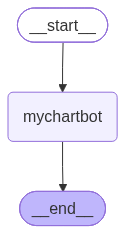

In [39]:
myappgraph

In [40]:
input_messages = {
    "messages": [
        HumanMessage(content="tell about tesala") 
    ]
}

In [41]:
myresult=myappgraph.invoke(input_messages)


MYBOT NODE
Current Messages: [HumanMessage(content='tell about tesala', additional_kwargs={}, response_metadata={}, id='b02b8dc1-b5cb-43d0-97f6-8c1c30fcd48e')]

Model Response: **Tesla, Inc.** (often simply “Tesla”) is an American electric‑vehicle (EV) and clean‑energy company headquartered in Palo Alto, California. Founded in 2003 by Martin Eberhard and Marc Tarpenning, it later brought in Elon Musk, JB Straubel, and Ian Wright as key early investors and leaders. Musk has served as CEO since 2008 and is the public face of the company.

---

## 1. Core Business Segments

| Segment | What It Does | Key Products |
|---------|--------------|--------------|
| **Automotive** | Design, manufacture, and sale of electric cars and related hardware | Model S, Model 3, Model X, Model Y, Cybertruck, Roadster (upcoming) |
| **Energy Generation & Storage** | Solar panels, solar roofs, and battery storage solutions | Solar Roof, Solar Panels, Powerwall, Powerpack, Megapack |
| **Software & Services*

## 4th workflow

In [43]:
response =llm.invoke("hi hello how are you?")
response.content

"Hello! I'm doing great—thanks for asking. How can I help you today?"

In [44]:
response.usage_metadata

{'input_tokens': 77,
 'output_tokens': 45,
 'total_tokens': 122,
 'output_token_details': {'reasoning': 19}}

In [45]:
from typing_extensions import TypedDict, NotRequired
from langchain_core.messages import AIMessage



In [46]:
class State(TypedDict):
    # User input
    question: str
    # Generated answer
    answer: NotRequired[str]
    # Complete model response
    response: NotRequired[AIMessage]
    # Token information
    input_tokens: NotRequired[int]
    output_tokens: NotRequired[int]
    total_tokens: NotRequired[int]

In [48]:
def llm_node(state: State):
    print("\n========================")
    print("LLM NODE")
    print("========================")
    
    response = llm.invoke(state["question"])
    print(
        "\nGenerated Answer:\n",
        response.content
    )
    
    # IMPORTANT:
    # We are NOT counting tokens here.
    # We simply save the complete AIMessage
    # so the next node can inspect its token metadata.
    return { "answer": response.content, "response": response}


In [50]:
def token_counter(state: State):
    print("\n========================")
    print("TOKEN COUNTER NODE")
    print("========================")
    response = state["response"]
    
    usage = response.usage_metadata or {}

    input_tokens = usage.get(
        "input_tokens"
    )

    output_tokens = usage.get(
        "output_tokens"
    )

    total_tokens = usage.get(
        "total_tokens"
    )

    print(
        "Input Tokens:",
        input_tokens
    )

    print(
        "Output Tokens:",
        output_tokens
    )

    print(
        "Total Tokens:",
        total_tokens
    )

    return {"input_tokens": input_tokens, "output_tokens": output_tokens, "total_tokens": total_tokens}

In [51]:
workflow = StateGraph(State)

In [52]:
workflow.add_node("llm_node", llm_node)
workflow.add_node("token_counter", token_counter)

In [53]:
workflow.add_edge(START, "llm_node")
workflow.add_edge("llm_node", "token_counter")
workflow.add_edge("token_counter", END)

In [54]:
app = workflow.compile()

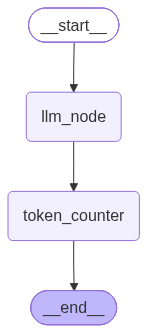

In [55]:
from IPython.display import Image, display

display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

In [56]:
result = app.invoke({"question": "Tell me about Tata Group in detail."})


LLM NODE

Generated Answer:
 ## Tata Group – A Comprehensive Overview

| Topic | Key Points |
|-------|------------|
| **Founded** | 1868 (Jamsetji Tata) |
| **Headquarters** | Mumbai, India |
| **Parent** | Tata Sons (holding company) |
| **Core Values** | “We do the right thing” – ethics, sustainability, community welfare |
| **Revenue (FY 2023‑24)** | ~₹4.8 trn (~US$60 bn) |
| **Employees** | ~450 000+ worldwide |
| **Market Cap** | ~US$150 bn (as of late 2023) |
| **Global Presence** | 100+ countries; 20+ manufacturing plants in 12 countries |

---

### 1. Historical Timeline

| Year | Milestone |
|------|-----------|
| **1868** | Jamsetji Tata founds *Tata Iron & Steel Works* in Jamshedpur. |
| **1878** | Launch of *Tata & Sons* trading firm. |
| **1908** | First *Tata Steel* plant in Jamshedpur. |
| **1919** | Establishment of *Tata Institute of Social Sciences* (TISS). |
| **1948** | *Tata Motors* founded (originally Tata Engineering Company). |
| **1955** | *Tata Consultancy S

# 5th and advance workflow

In [60]:
import os
import json
from typing import TypedDict, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
# LangChain
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.document_loaders import (
    TextLoader,
    DirectoryLoader,
)
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_tavily import TavilySearch
# LangGraph
from langgraph.graph import (
    StateGraph,
    START,
    END,
)

In [62]:
MODEL_NAME = "openai/gpt-oss-20b"
llm = ChatGroq(
    model=MODEL_NAME,
    temperature=0.6,
    reasoning_format="hidden"
)

In [63]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.3', 'langchain': '1.4.3'}}, output_version=None, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001F296852CD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F296853750>, model_name='openai/gpt-oss-20b', temperature=0.6, reasoning_format='hidden', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None)

In [64]:
embeddings = HuggingFaceEmbeddings(model_name="BAAI/bge-small-en-v1.5")

In [65]:
embedding_vector = embeddings.embed_query("Hello")
print("Embedding Dimension:",len(embedding_vector))

Embedding Dimension: 384


In [67]:
Data_Path = "E:\MAHA\AIPRO\Agentic10PM\Langgraph\Data"

In [68]:
loader = DirectoryLoader(
    Data_Path,
    glob="*.txt",
    loader_cls=TextLoader,
    loader_kwargs={
        "encoding": "utf-8"
    }
)

In [69]:
docs = loader.load()
print(
    "Total documents loaded:",
    len(docs)
)

Total documents loaded: 1


In [70]:
docs

[Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='The United States economy is one of the largest and most diversified economies in the world. It is driven mainly by services, technology, finance, healthcare, manufacturing, retail, and consumer spending. The country has a strong startup ecosystem and is home to many global companies such as \nMicrosoft, Apple, Amazon, Google, and Tesla. Innovation, research, \nadvanced infrastructure, and access to capital support long-term economic growth. \nThe U.S. dollar is widely used in international trade and is also a major global reserve currency.\n The country exports aircraft, software, pharmaceuticals, industrial equipment, agricultural goods,\n  and financial services. Major economic challenges include inflation, public debt, income inequality,\n   housing costs, and competition from other global economies. The Federal Reserve manages monetary \n   policy by adjusting interest rates a

[Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='The United States economy is one of the largest and most diversified economies in the world. It is driven mainly by services, technology, finance, healthcare, manufacturing, retail, and consumer spending. The country has a strong startup ecosystem and is home to many global companies such as \nMicrosoft, Apple, Amazon, Google, and Tesla. Innovation, research, \nadvanced infrastructure, and access to capital support long-term economic growth. \nThe U.S. dollar is widely used in international trade and is also a major global reserve currency.\n The country exports aircraft, software, pharmaceuticals, industrial equipment, agricultural goods,\n  and financial services. Major economic challenges include inflation, public debt, income inequality,\n   housing costs, and competition from other global economies. The Federal Reserve manages monetary \n   policy by adjusting interest rates and controlling liquidity. Future growth is expected to\n    be influenced by artificial intelligence, clean energy, semiconductors,')]

In [71]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

In [72]:
new_docs = text_splitter.split_documents(
    docs
)


print(
    "Total chunks:",
    len(new_docs)
)

Total chunks: 14


In [73]:
new_docs

[Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='The United States economy is one of the largest and most diversified economies in the world. It is'),
 Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='in the world. It is driven mainly by services, technology, finance, healthcare, manufacturing,'),
 Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='manufacturing, retail, and consumer spending. The country has a strong startup ecosystem and is'),
 Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='ecosystem and is home to many global companies such as'),
 Document(metadata={'source': 'E:\\MAHA\\AIPRO\\Agentic10PM\\Langgraph\\Data\\sample.txt'}, page_content='Microsoft, Apple, Amazon, Google, and Tesla. Innovation, research,'),
 Document(metadata={'source': 'E:\\MAHA\\AI

In [74]:
vector_store = Chroma(
    collection_name="usa_economy",
    embedding_function=embeddings
)

In [75]:

vector_store.add_documents(
    documents=new_docs
)

['94fa22c0-229e-4474-9757-d84bf1101233',
 '213de6d9-c07c-44c9-811d-a3cfe1c7c918',
 '510a4e56-d21a-40a9-bde6-5de7de7b0763',
 '0a5b0b2a-f676-4dab-853d-8fcf84540cfe',
 'c719a399-1621-4f63-b890-f7613319d18c',
 'b97c9798-0d47-44c7-ba3a-44d5f06f0f20',
 '8cd4bc02-3e31-4fe9-b0f0-46be4b1ac945',
 '4e05845f-e09d-4d19-af66-e2feb4f5ab57',
 'a8a4bd36-938e-4a6b-998d-fb2593d51ae6',
 'd4dd8cf6-89b6-4f02-a2f7-c8f3748a141f',
 'd9a94c65-cdcd-4f36-919e-5d533677a1eb',
 '6bd58fbc-adeb-42a2-bdad-ff5f1f6d77f8',
 '27b79c76-add8-414e-add6-2da2948cd717',
 '844644af-8a99-45ca-a642-94d5626cfbb7']

In [76]:
retriever = vector_store.as_retriever(
    search_kwargs={
        "k": 3
    }
)

In [77]:
test_documents = retriever.invoke(
    "What is GDP of USA?"
)

for document in test_documents:

    print(
        document.page_content
    )

    print("-" * 50)

The United States economy is one of the largest and most diversified economies in the world. It is
--------------------------------------------------
housing costs, and competition from other global economies. The Federal Reserve manages monetary
--------------------------------------------------
The U.S. dollar is widely used in international trade and is also a major global reserve currency.
--------------------------------------------------


In [79]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(
    max_results=5,
    search_depth="advanced",
    topic="general"
)

In [80]:
result = web_search.invoke({"query": "What is the latest AI news?"})
print(result)

{'query': 'What is the latest AI news?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://en.wikipedia.org/wiki/Artificial_intelligence', 'title': 'Artificial intelligence', 'content': 'In November 2023, the first global AI Safety Summit was held in Bletchley Park in the UK to discuss the near and far term risks of AI and the possibility of mandatory and voluntary regulatory frameworks.( 28 countries including the United States, China, and the European Union issued a declaration at the start of the summit, calling for international co-operation to manage the challenges and risks of artificial intelligence.( In May 2024 at the AI Seoul Summit, 16 global AI tech companies agreed to safety commitments on the development of AI.( [...] ### Web search\n\nMicrosoft introduced Copilot Search in February 2023 under the name Bing Chat. Copilot Search provides AI-generated summaries.(\n\nGenerative AI features added to Google Search include AI Overviews in M

In [97]:
class RouteDecision(BaseModel):
    route: Literal["RAG","LLM","WEB"] = Field(description="Node that should handle the user query")
    reasoning: str = Field(description="Reason for selecting this node")

In [98]:
RouteDecision.model_json_schema()

{'properties': {'route': {'description': 'Node that should handle the user query',
   'enum': ['RAG', 'LLM', 'WEB'],
   'title': 'Route',
   'type': 'string'},
  'reasoning': {'description': 'Reason for selecting this node',
   'title': 'Reasoning',
   'type': 'string'}},
 'required': ['route', 'reasoning'],
 'title': 'RouteDecision',
 'type': 'object'}

In [112]:
llm.invoke("tell me about india?")

AIMessage(content='**India – A Quick Overview**\n\n| Topic | Highlights |\n|-------|------------|\n| **Location & Size** | 7th largest country in the world (≈3.29\u202fmillion km²), bordered by Pakistan, China, Nepal, Bhutan, Bangladesh, Myanmar, and the Indian Ocean. |\n| **Population** | ~1.4\u202fbillion (2024 estimate), >\u202f50\u202f% under 25\u202fyears old. |\n| **Capital** | New Delhi (administrative & political hub). |\n| **Major Cities** | Mumbai (financial), Bengaluru (IT), Hyderabad (tech & pharma), Chennai (engineering), Kolkata (culture & trade). |\n| **Official Languages** | 22 scheduled languages; Hindi (official, ~41\u202f% speakers) and English (associate official, widely used in business & education). |\n| **Religion** | Hinduism (≈80\u202f%), Islam (≈14\u202f%), Christianity, Sikhism, Buddhism, Jainism, and others. |\n| **Political System** | Federal parliamentary republic. President is head of state; Prime Minister is head of government. 29 states + 9 union territ

In [99]:
supervisor_model = llm.with_structured_output(schema=RouteDecision.model_json_schema(),method="json_schema")

In [100]:
supervisor_model.invoke("tell me about india?")

{'route': 'LLM',
 'reasoning': 'User requests general information about India, which can be provided by the language model.'}

In [94]:
supervisor_model.invoke("What is GDP of USA?")

{'route': 'LLM',
 'reasoning': 'Answering a factual question about the GDP of the United States.'}

In [95]:
supervisor_model.invoke("can you tell me AI news today?")

{'route': 'WEB',
 'reasoning': 'User requests up-to-date AI news, which requires browsing the web for the latest information.'}

In [105]:
supervisor_model.invoke("can you tell me about today the USA current GDP?")

{'route': 'WEB',
 'reasoning': 'User requests the current USA GDP, which requires up-to-date data that is best retrieved from the web.'}

In [106]:
class ValidationResult(BaseModel):
    passed: bool = Field(description="True if the generated answer passes validation")
    score: int = Field(ge=0,le=10,description="Quality score from 0 to 10")
    feedback: str = Field(description="Reason for validation result")


In [110]:
validator_model = llm.with_structured_output(schema=ValidationResult.model_json_schema(),method="json_schema")
validator_model

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.3', 'langchain': '1.4.3'}}, output_version=None, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001F296852CD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F296853750>, model_name='openai/gpt-oss-20b', temperature=0.6, reasoning_format='hidden', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None), kwargs={'response_format': {'type': 'json_schema',

In [111]:
class AgentState(TypedDict, total=False):
    # Original user query
    question: str
    # Supervisor decision
    route: str
    # Supervisor reasoning
    route_reasoning: str
    # Context from RAG / Web
    context: str
    # Answer generated by RAG / LLM / Web
    draft_answer: str
    # Validation result
    validation_passed: bool
    validation_score: int
    validation_feedback: str
    # Retry information
    attempts: int
    # Keep track of previously used routes
    used_routes: list[str]
    # Answer shown to user only after validation
    final_answer: str

In [113]:
def supervisor_node(state: AgentState):
    print("\n==============================")
    print("SUPERVISOR NODE")
    print("==============================")
    question = state["question"]
    previous_feedback = state.get("validation_feedback","")
    used_routes = state.get("used_routes",[])
    attempts = state.get("attempts",0)
    supervisor_prompt = f"""
You are the supervisor of an AI system.

Your responsibility is to decide which node should answer
the user's question.

You have three possible nodes:

1. RAG

Use RAG when:
- the question is related to the USA economy
- GDP of USA
- industrial growth of USA
- US economic sectors
- US debt
- US economic strengths
- USA economic information contained in our internal documents

The RAG knowledge base mainly contains information
about the United States economy.


2. WEB

Use WEB when:
- the user asks for current information
- today
- latest
- realtime
- recent news
- current stock priceent weather
- latest economi
- currc information
- information that may have changed recently
- internal RAG documents may be outdated


3. LLM

Use LLM when:
- the question is general knowledge
- casual conversation
- greeting
- conceptual question
- question unrelated to the USA knowledge base
- information does not require current internet data


User Question:
{question}


Routes already attempted:

{used_routes}


Previous validation feedback:

{previous_feedback}


Important:

If a previous answer failed validation,
use the validation feedback to decide whether another
information source should be selected.

Return the best route.
"""


    decision = supervisor_model.invoke(supervisor_prompt)
    route = decision["route"]
    reasoning = decision["reasoning"]

    print("Selected Route:",route)
    print("Reasoning:",reasoning)
    updated_routes = (used_routes + [route])


    return {

        "route": route,

        "route_reasoning": reasoning,

        "attempts": attempts + 1,

        "used_routes": updated_routes,

        # Clear previous attempt
        "context": "",

        "draft_answer": "",

    }

In [114]:

def router(state: AgentState):

    print(
        "\n-> ROUTER ->"
    )


    route = state["route"]


    print(
        "Routing to:",
        route
    )


    return route


In [115]:
def format_docs(documents):
    return "\n\n".join(document.page_content for document in documents)

In [116]:
def rag_node(state: AgentState):
    print("\n==============================")
    print("RAG NODE")
    print("==============================")
    question = state["question"]
    # -----------------------------------
    # Retrieve documents
    # -----------------------------------
    retrieved_docs = retriever.invoke(question)
    context = format_docs(retrieved_docs)
    print("Retrieved Documents:",len(retrieved_docs))

    # -----------------------------------
    # Generate answer
    # -----------------------------------

    rag_prompt = f"""
You are a question-answering assistant.

Answer the user's question using ONLY the supplied
retrieved context.

If the context does not contain enough information,
clearly say that the available internal knowledge
is insufficient.

Do not invent facts.

User Question:

{question}


Retrieved Context:

{context}


Generate a clear and concise answer.
"""
    response = llm.invoke(rag_prompt)
    
    answer = response.content

    print("RAG Answer:", answer)


    return {

        "context": context,

        "draft_answer": answer,

    }


In [117]:
def llm_node(state: AgentState):
    print("\n==============================")
    print("LLM NODE")
    print("==============================")
    question = state["question"]
    prompt = f"""
Answer the following question using your general
knowledge.

Give a clear, accurate and useful response.

If the question requires current or real-time information
that you cannot reliably know, explicitly mention that
real-time information should be checked.

Question:

{question}
"""
    response = llm.invoke(prompt)
    answer = response.content
    print("LLM Answer:",answer)
    
    return {

        "context": "",

        "draft_answer": answer,

    }


In [118]:
def web_node(state: AgentState):
    print(
        "\n=============================="
    )

    print(
        "WEB SEARCH NODE"
    )

    print(
        "=============================="
    )


    question = state["question"]


    # -----------------------------------
    # Search realtime internet
    # -----------------------------------

    search_result = web_search.invoke(

        {
            "query": question
        }

    )


    # -----------------------------------
    # Convert returned data to text
    # -----------------------------------

    if isinstance(
        search_result,
        dict
    ):

        results = search_result.get(
            "results",
            []
        )


        if results:

            web_context_parts = []


            for result in results:

                title = result.get(
                    "title",
                    ""
                )

                url = result.get(
                    "url",
                    ""
                )

                content = result.get(
                    "content",
                    ""
                )


                web_context_parts.append(

                    f"""
Title:
{title}

URL:
{url}

Content:
{content}
"""

                )


            web_context = "\n\n".join(
                web_context_parts
            )


        else:

            web_context = json.dumps(

                search_result,

                indent=2,

                ensure_ascii=False,

                default=str

            )


    else:

        web_context = str(
            search_result
        )


    print(
        "Web search completed."
    )


    # -----------------------------------
    # Generate answer using web context
    # -----------------------------------

    web_prompt = f"""
You are answering a user question using current
web-search results.

Use the web information below to answer the question.

Do not fabricate facts.

When useful, mention the source names or URLs
available in the search result.

User Question:

{question}


Web Search Results:

{web_context}


Generate the best answer based on the current
web information.
"""


    response = llm.invoke(
        web_prompt
    )


    answer = response.content


    print(
        "WEB Answer:",
        answer
    )


    return {

        "context": web_context,

        "draft_answer": answer,

    }



In [119]:
def validator_node(
    state: AgentState
):

    print(
        "\n=============================="
    )

    print(
        "VALIDATOR NODE"
    )

    print(
        "=============================="
    )


    question = state["question"]

    route = state["route"]

    answer = state["draft_answer"]

    context = state.get(
        "context",
        ""
    )


    validation_prompt = f"""
You are the quality-control validator of an AI system.

Evaluate whether the generated answer is acceptable.


USER QUESTION:

{question}


NODE USED:

{route}


SOURCE CONTEXT:

{context}


GENERATED ANSWER:

{answer}


Validate the answer using these criteria:


1. RELEVANCE

Does the answer directly answer the user's question?


2. CORRECTNESS

Does the answer appear logically and factually correct
based on the available evidence?


3. COMPLETENESS

Does it provide enough information to answer the question?


4. HALLUCINATION

Does the answer make unsupported claims?


5. SOURCE GROUNDING

If NODE USED = RAG:

The answer must be supported by the retrieved context.


If NODE USED = WEB:

The answer must be supported by the web search context.


If NODE USED = LLM:

The answer should be suitable for general stable knowledge
and must not pretend to know unavailable real-time facts.


SCORING:

0-4  = poor
5-6  = needs improvement
7    = acceptable but weak
8-10 = good


PASS only if the score is 7 or higher and there is no
major factual or grounding problem.


Return:

passed
score
feedback
"""


    result = validator_model.invoke(
        validation_prompt
    )


    passed = result["passed"]

    score = result["score"]

    feedback = result["feedback"]


    print(
        "Validation Passed:",
        passed
    )

    print(
        "Score:",
        score
    )

    print(
        "Feedback:",
        feedback
    )


    return {

        "validation_passed": passed,

        "validation_score": score,

        "validation_feedback": feedback,

    }


In [120]:
def validation_router(
    state: AgentState
):

    print(
        "\n-> VALIDATION ROUTER ->"
    )


    # -----------------------------------
    # Validation passed
    # -----------------------------------

    if state["validation_passed"]:

        print(
            "Validation PASSED"
        )

        return "Final"


    # -----------------------------------
    # Too many attempts
    # -----------------------------------

    if state.get("attempts",0) >= MAX_ATTEMPTS:
        print(
            "Maximum attempts reached"
        )

        return "Failed"


    # -----------------------------------
    # Validation failed -> supervisor
    # -----------------------------------

    print(
        "Validation FAILED"
    )

    print(
        "Returning to Supervisor..."
    )


    return "Supervisor"


In [121]:

def final_node(
    state: AgentState
):

    print(
        "\n=============================="
    )

    print(
        "FINAL ANSWER NODE"
    )

    print(
        "=============================="
    )


    answer = state["draft_answer"]


    return {

        "final_answer": answer

    }


In [122]:

def failed_node(
    state: AgentState
):

    print(
        "\n=============================="
    )

    print(
        "VALIDATION FAILED AFTER RETRIES"
    )

    print(
        "=============================="
    )


    message = (
        "The system could not generate a sufficiently "
        "validated answer after multiple attempts."
    )


    return {

        "final_answer": message

    }

In [123]:
workflow = StateGraph(AgentState)

In [124]:
workflow.add_node("Supervisor",supervisor_node)
workflow.add_node("RAG",rag_node)
workflow.add_node("LLM",llm_node)
workflow.add_node("WEB",web_node)
workflow.add_node("Validator",validator_node)
workflow.add_node("Final",final_node)
workflow.add_node("Failed",failed_node)

In [125]:
workflow.add_edge(START,"Supervisor")

workflow.add_conditional_edges("Supervisor",
                            router,
    {
        "RAG": "RAG",

        "LLM": "LLM",

        "WEB": "WEB",

    }

)

#fan-in
workflow.add_edge("RAG","Validator")
workflow.add_edge("LLM","Validator")
workflow.add_edge("WEB","Validator")


workflow.add_conditional_edges(
    "Validator",
    validation_router,
    {
        "Final": "Final",
        "Supervisor": "Supervisor",
        "Failed": "Failed",

    }

)
workflow.add_edge("Final",END)
workflow.add_edge("Failed",END)

In [126]:
app = workflow.compile()
print(
    "\nGraph compiled successfully."
)


Graph compiled successfully.


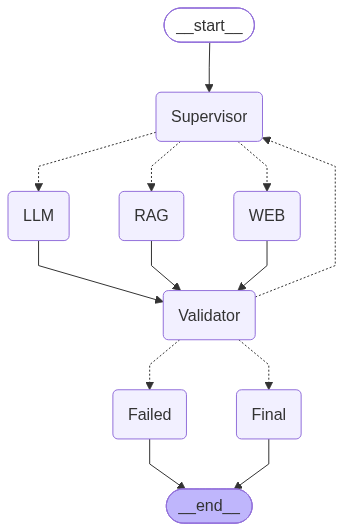

In [127]:
from IPython.display import (
    Image,
    display,
)

display(

    Image(

        app.get_graph().draw_mermaid_png()

    )

)

In [128]:
def ask_agent(question: str):

    initial_state = {

        "question": question,

        "attempts": 0,

        "used_routes": [],

        "validation_feedback": "",

        "validation_passed": False,

        "validation_score": 0,

        "context": "",

        "draft_answer": "",

        "final_answer": "",

    }


    result = app.invoke(

        initial_state,

        {
            "recursion_limit": 30
        }

    )


    print(
        "\n\n================================"
    )

    print(
        "FINAL RESULT"
    )

    print(
        "================================"
    )


    print(
        "Question:"
    )

    print(
        result["question"]
    )


    print(
        "\nFinal Route:"
    )

    print(
        result.get(
            "route"
        )
    )


    print(
        "\nRoutes Tried:"
    )

    print(
        result.get(
            "used_routes"
        )
    )


    print(
        "\nValidation Score:"
    )

    print(
        result.get(
            "validation_score"
        )
    )


    print(
        "\nValidation Feedback:"
    )

    print(
        result.get(
            "validation_feedback"
        )
    )


    print(
        "\nFinal Answer:"
    )

    print(
        result["final_answer"]
    )


    return result

In [129]:
result = ask_agent("hi can you help me?")


SUPERVISOR NODE
Selected Route: LLM
Reasoning: The user’s greeting is a general, casual question that does not require specific or current information about the USA economy, nor does it request real-time data. It is best handled by the LLM node.

-> ROUTER ->
Routing to: LLM

LLM NODE
LLM Answer: Sure thing! I’m here to help. What do you need assistance with? Whether it’s a question about a specific topic, help with a task, or just looking for some guidance, just let me know and I’ll do my best to assist.

VALIDATOR NODE
Validation Passed: True
Score: 9
Feedback: The response is relevant, correct, and appropriately general for the user's request. No factual or grounding issues are present.

-> VALIDATION ROUTER ->
Validation PASSED

FINAL ANSWER NODE


FINAL RESULT
Question:
hi can you help me?

Final Route:
LLM

Routes Tried:
['LLM']

Validation Score:
9

Validation Feedback:
The response is relevant, correct, and appropriately general for the user's request. No factual or grounding 

In [130]:
result = ask_agent("can you tell me the current GDP of china?")


SUPERVISOR NODE
Selected Route: WEB
Reasoning: The user asks for the current GDP of China, which requires up-to-date data not covered by the USA-focused RAG knowledge base. Therefore, the WEB node should handle this request.

-> ROUTER ->
Routing to: WEB

WEB SEARCH NODE
Web search completed.
WEB Answer: **China’s current (2026) nominal GDP**

According to the most recent data from the International Monetary Fund (IMF) and reported by Worldometer, China’s nominal Gross Domestic Product (GDP) for 2026 is **about $21.55 trillion USD** (current dollars).  

- **Growth rate (2026)**: 4.5 %  
- **GDP per capita (2026)**: $15,371 (≈ $31,786 PPP)  

These figures place China as the world’s second‑largest economy by nominal GDP, after the United States.

**Sources**

- *Worldometer – China GDP (2026)*: “Nominal (current) Gross Domestic Product (GDP) of China is $21.55 trillion as of 2026, according to the International Monetary Fund (IMF).”  
- *Wikipedia – Economy of China*: “GDP (nominal) –

In [131]:
result = ask_agent("What are the major economic challenges of the USA?")


SUPERVISOR NODE
Selected Route: RAG
Reasoning: The question specifically asks about the major economic challenges of the USA, which falls squarely under the RAG node’s scope for U.S. economic topics.

-> ROUTER ->
Routing to: RAG

RAG NODE
Retrieved Documents: 3
RAG Answer: The major economic challenges highlighted in the context are:

- **Inflation**  
- **Public debt**  
- **Income (likely referring to income inequality)**  
- **Housing costs**  
- **Competition from other global economies**  

The Federal Reserve is noted as managing monetary policy to address these issues.

VALIDATOR NODE
Validation Passed: True
Score: 8
Feedback: The answer is relevant, factually correct, and grounded in the provided context. It lists the major economic challenges mentioned in the source and does not introduce unsupported claims. The response is concise yet sufficiently complete for the user's question.

-> VALIDATION ROUTER ->
Validation PASSED

FINAL ANSWER NODE


FINAL RESULT
Question:
What ar

In [132]:
result = ask_agent("can you give me current update of the usa and iran war?")


SUPERVISOR NODE
Selected Route: WEB
Reasoning: User requests a current update on the USA and Iran war, requiring up-to-date information that may have changed recently; thus the WEB node should be used.

-> ROUTER ->
Routing to: WEB

WEB SEARCH NODE
Web search completed.
WEB Answer: **Current status of the U.S.–Iran conflict (as of early November 2026)**  

| Item | What’s happening | Source |
|------|-----------------|--------|
| **Cease‑fire / interim agreements** | A two‑week cease‑fire was reached on 7 April 2026, followed by a Pakistan‑mediated interim deal on 14 June 2026 that reopened the Strait of Hormuz, ended fighting between Hezbollah and Israel in Lebanon, and called for a 60‑day pause in hostilities.  Both sides have accused each other of violations and the agreement has not yet produced a lasting settlement. | CFR Global Conflict Tracker |
| **Ongoing hostilities** | Mutual strikes continue.  The U.S. has carried out airstrikes on Iranian targets (e.g., Qeshm Island, miss

In [133]:
result = ask_agent("when usa and iran war end?")


SUPERVISOR NODE
Selected Route: LLM
Reasoning: The question asks about a speculative future event (end of a hypothetical war between the USA and Iran), which is general knowledge and not current data or related to the USA economy. Therefore the LLM node is appropriate.

-> ROUTER ->
Routing to: LLM

LLM NODE
LLM Answer: There is no ongoing war between the United States and Iran. The two countries have had a complex and sometimes tense relationship, but they have not engaged in a declared war with each other.  

Because no conflict exists, it is impossible to predict an “end date” for a war that has not happened. Any speculation about a future conflict would be purely hypothetical and not based on current events or official statements.

If you’re looking for up‑to‑date information on U.S.–Iran relations, I recommend consulting reputable news outlets, government briefings, or analyses from think‑tanks that specialize in international affairs. These sources will provide the most reliable